# 03c · Path patching: testing the mechanism with interventions

The mechanism suggested by 3a/3b:
1. the situation is moved **onto the phrase tokens** (layers ≈ 8–15), where the incongruity is computed;
2. the result is gathered at the **question tokens** (layers ≈ 13–18);
3. at the **last token**, heads of layer 18 (h15, h18, h4, h13, h16) act as a **switch**: they read the question and
   push towards "No", but when situation and phrase are incongruent they look at the end of the phrase instead;
   **m18** then writes most of the sarcasm direction.

Four tests (situation-swap and phrase-swap pairs, discovery and held-out; recovery R = (d − d_corr)/(d_clean − d_corr)):

| test | question | how |
|---|---|---|
| 1 · switch | is the effect of the layer-18 heads due to *where they look* or *what they read*? | at the last token, clean pattern × corrupted values vs corrupted pattern × clean values |
| 2 · knockout | are the layer-18 heads and m18 necessary? | mean-ablate them at the last token; S−P/N gap and triple accuracy |
| 3 · route | must the information pass through the phrase and the question tokens? | patch / block the attention outputs at those positions over a range of layers |
| 4 · movers | which heads move the information into the phrase and the question tokens? | patch each head at those positions |

**Runtime:** T4; about 20–30 minutes. Needs the results of 03a on Drive (key heads).

## Setup

In [1]:
# Get (or update) the code from GitHub
import os, sys
REPO = "https://github.com/vasilis-pantzos/sarcasm-proposal.git"
ROOT = "/content/sarcasm-proposal"
if not os.path.exists(ROOT):
    !git clone -q {REPO} {ROOT}
else:
    !git -C {ROOT} pull -q
os.chdir(ROOT)
sys.path.insert(0, ROOT)
%pip install -q -U accelerate bitsandbytes

In [2]:
import os, json, time, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from src.model import load_model, model_info, DEV_MODEL, MAIN_MODEL
from src.prompts import load_dataset, encode, make_pairs, data_tag, REGIONS
from src.patching import score_pairs, keep_correct, head_patching, recovery, mean_and_se
from src.metric import triple_accuracy
from src.pathpatch import pattern_value_patching, mean_last, ablate_d, route_patching
from src.utils import mount_drive, results_dir, cached, set_seed

# ---------------- settings ----------------
MODEL = MAIN_MODEL          # DEV_MODEL (3B) for quick tests
DATA = "v2"
LAYER = 18                  # the layer of the switch heads and of m18
N_DISC, N_HELD = 20, 12     # pairs per experiment
N_KO_DISC, N_KO_HELD = 100, 60   # triples for the knockout test
PHRASE_LAYERS = list(range(8, 16))     # situation -> phrase tokens
QUESTION_LAYERS = list(range(12, 18))  # -> question tokens
FINAL_LAYERS = list(range(16, 20))     # -> last token
# ------------------------------------------
TAG_MODEL = MODEL.split("/")[-1]
TAG = TAG_MODEL + data_tag(DATA)
SUB = f"03c_path_patching/{TAG}"
mount_drive()
print("results go to:", results_dir(SUB))
set_seed(0)

Mounted at /content/drive
results go to: /content/drive/MyDrive/sarcasm/03c_path_patching/Qwen2.5-7B-Instruct_data-v2


In [3]:
t0 = time.time()
model, tok = load_model(MODEL)
INFO = model_info(model)
L, H = INFO["n_layers"], INFO["n_heads"]
print(MODEL, INFO, f"loaded in {(time.time() - t0) / 60:.1f} min")
df = load_dataset(DATA).sort_values(["split", "triple_id", "condition"]).reset_index(drop=True)

ww = pd.read_csv(os.path.join(results_dir(f"03a_direction/{TAG}"), "who_writes.csv"))
KEY = [int(c.split(".h")[1]) for c in ww.component if c.startswith(f"a{LAYER}.h")][:5]
print(f"key heads of layer {LAYER}:", KEY)

rng = np.random.default_rng(0)
PAIRS = {}
for e in ["situation", "phrase"]:
    for split, n in [("discovery", N_DISC), ("heldout", N_HELD)]:
        ps = keep_correct(score_pairs(model, tok, make_pairs(df, tok, e, split=split)))
        PAIRS[(e, split)] = [ps[i] for i in rng.permutation(len(ps))][:n]
print({k: len(v) for k, v in PAIRS.items()})
R_ = lambda d, p: (d - p.info["d_corrupted"]) / (p.info["d_clean"] - p.info["d_corrupted"])

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen/Qwen2.5-7B-Instruct {'n_layers': 28, 'n_heads': 28, 'n_kv_heads': 4, 'd_model': 3584, 'head_dim': 128} loaded in 1.3 min
key heads of layer 18: [15, 18, 4, 13, 16]
{('situation', 'discovery'): 20, ('situation', 'heldout'): 12, ('phrase', 'discovery'): 20, ('phrase', 'heldout'): 12}


## 1 · Switch: where the heads look vs what they read

Denoising at the last token of layer 18, R of the corrupted input with the head outputs recombined. If the
**pattern** variant recovers most of the **full** variant, the effect is due to *where the heads look*.

[saved]  /content/drive/MyDrive/sarcasm/03c_path_patching/Qwen2.5-7B-Instruct_data-v2/switch_L18.pt
0.6 min


variant                             full  pattern  value
experiment split     heads                              
situation  discovery 5 key heads   0.076   -0.007  0.252
                     h15          -0.025   -0.014  0.062
                     h18           0.010    0.014  0.033
                     h4            0.062    0.016  0.095
                     h13           0.013   -0.005  0.012
                     h16           0.012    0.007  0.013
                     all 28 heads  0.110    0.004  0.274
           heldout   5 key heads   0.300   -0.007  0.349
                     h15           0.068    0.001  0.092
                     h18           0.052    0.012  0.057
                     h4            0.100   -0.007  0.119
                     h13           0.013   -0.003  0.010
                     h16           0.006    0.001  0.009
                     all 28 heads  0.347   -0.001  0.389
phrase     discovery 5 key heads   0.178   -0.006  0.272
                     h15           0.019    0.001  0.065
                     h18          -0.021   -0.003  0.004
                     h4            0.049    0.009  0.074
                     h13           0.078   -0.011  0.075
                     h16           0.011   -0.002  0.006
                     all 28 heads  0.232   -0.007  0.320
           heldout   5 key heads   0.253    0.026  0.309
                     h15           0.057    0.020  0.088
                     h18          -0.030    0.013 -0.010
                     h4           -0.005    0.034  0.021
                     h13           0.191   -0.001  0.181
                     h16           0.056    0.013  0.037
                     all 28 heads  0.300    0.017  0.343

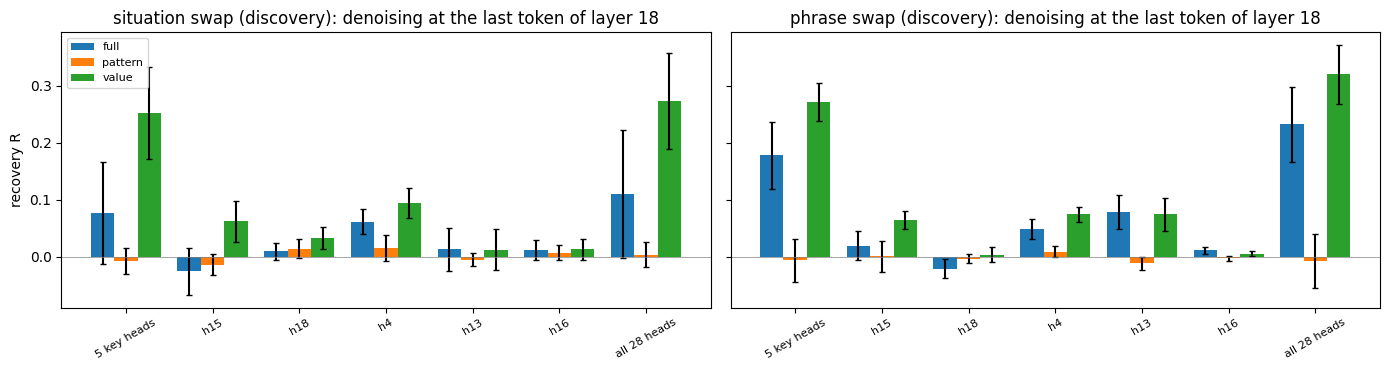

In [4]:
SETS = {f"{len(KEY)} key heads": KEY, **{f"h{h}": [h] for h in KEY}, f"all {H} heads": list(range(H))}

def run_switch():
    out = {}
    for key, ps in PAIRS.items():
        out[key] = [pattern_value_patching(model, tok, p, LAYER, SETS) for p in ps]
    return out

t0 = time.time()
SW = cached(f"switch_L{LAYER}", run_switch, sub=SUB)
print(f"{(time.time() - t0) / 60:.1f} min")
rows = []
for (e, split), res in SW.items():
    ps = PAIRS[(e, split)]
    for name in SETS:
        for var in ["full", "pattern", "value"]:
            r = np.array([R_(x[name][var], p) for x, p in zip(res, ps)])
            rows.append(dict(experiment=e, split=split, heads=name, variant=var, R=r.mean(), se=r.std(ddof=1) / np.sqrt(len(r))))
SWT = pd.DataFrame(rows)
display(SWT.pivot_table(index=["experiment", "split", "heads"], columns="variant", values="R", sort=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, e in zip(axes, ["situation", "phrase"]):
    s = SWT[(SWT.experiment == e) & (SWT.split == "discovery")]
    x = np.arange(len(SETS))
    for j, var in enumerate(["full", "pattern", "value"]):
        v = s[s.variant == var].set_index("heads").loc[list(SETS)]
        ax.bar(x + (j - 1) * 0.27, v.R, 0.27, yerr=1.96 * v.se, capsize=2, label=var)
    ax.set_xticks(x); ax.set_xticklabels(list(SETS), rotation=30, fontsize=8); ax.axhline(0, c="gray", lw=0.5)
    ax.set_title(f"{e} swap (discovery): denoising at the last token of layer {LAYER}")
axes[0].set_ylabel("recovery R"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "switch_pattern_vs_value.png"), dpi=150); plt.show()

## 2 · Knockout: mean-ablate the switch heads and m18 at the last token

On whole triples (P, S, N), discovery and held-out. "gap" = mean d(S) − mean d(P, N); shown as a share of the gap
without ablation. Control: 5 random heads of the same layer (3 draws).

[saved]  /content/drive/MyDrive/sarcasm/03c_path_patching/Qwen2.5-7B-Instruct_data-v2/knockout_L18_n100_60.pt
1.5 min


,,gap,triple_accuracy,Yes rate P,Yes rate S,Yes rate N,share of gap
split,ablation,,,,,,
discovery,none,9.868,0.790,0.070,0.720,0.310,1.000
heldout,none,10.323,0.700,0.167,0.867,0.517,1.000
discovery,key heads,6.961,0.780,0.060,0.660,0.280,0.705
heldout,key heads,6.960,0.767,0.100,0.817,0.400,0.674
discovery,m18,7.124,0.710,0.060,0.670,0.340,0.722
heldout,m18,7.556,0.617,0.117,0.833,0.583,0.732
discovery,key heads + m18,5.970,0.740,0.050,0.650,0.280,0.605
heldout,key heads + m18,6.097,0.733,0.083,0.800,0.433,0.591
discovery,all heads of layer 18,6.529,0.770,0.040,0.650,0.280,0.662


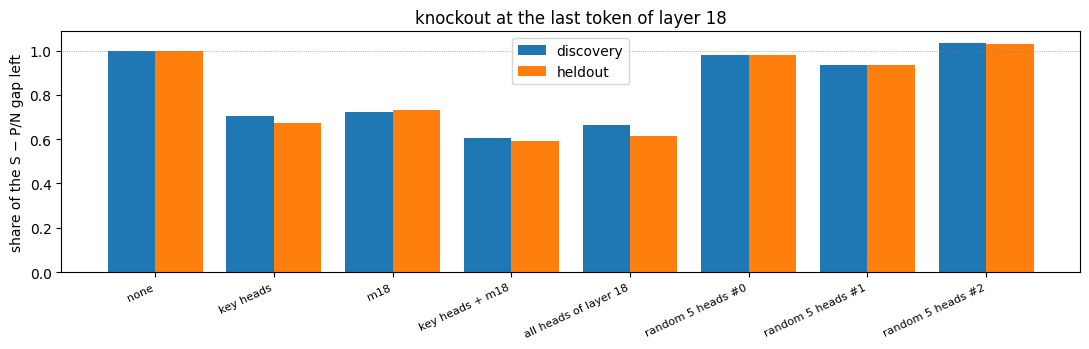

In [5]:
tids = list(rng.choice(df[df.split == "discovery"].triple_id.unique(), N_KO_DISC, replace=False))
tids += list(rng.choice(df[df.split == "heldout"].triple_id.unique(), N_KO_HELD, replace=False))
KO = df[df.triple_id.isin(tids)].reset_index(drop=True)
KO_IDS = [encode(tok, r).ids for r in KO.itertuples()]
ref_ids = [encode(tok, r).ids for r in df[(df.split == "discovery") & ~df.triple_id.isin(tids)].sample(300, random_state=0).itertuples()]

others = [h for h in range(H) if h not in KEY]
VARIANTS = {"none": dict(), "key heads": dict(heads=KEY), f"m{LAYER}": dict(mlp=True),
            f"key heads + m{LAYER}": dict(heads=KEY, mlp=True), f"all heads of layer {LAYER}": dict(heads=list(range(H))),
            **{f"random 5 heads #{s}": dict(heads=list(np.random.default_rng(10 + s).choice(others, min(5, len(others)), replace=False))) for s in range(3)}}

def run_ko():
    zm, mm = mean_last(model, ref_ids, LAYER)
    return {k: ablate_d(model, tok, KO_IDS, LAYER, zmean=zm, mmean=mm, **v) for k, v in VARIANTS.items()}

t0 = time.time()
KOD = cached(f"knockout_L{LAYER}_n{N_KO_DISC}_{N_KO_HELD}", run_ko, sub=SUB)
print(f"{(time.time() - t0) / 60:.1f} min")
rows = []
for k, d in KOD.items():
    for split in ["discovery", "heldout"]:
        m = (KO.split == split).values
        sub = KO[m].assign(d=d[m])
        piv = sub.pivot(index="triple_id", columns="condition", values="d")
        gap = sub[sub.condition == "S"].d.mean() - sub[sub.condition != "S"].d.mean()
        rows.append(dict(ablation=k, split=split, gap=gap, triple_accuracy=triple_accuracy(piv.P, piv.S, piv.N),
                         **{f"Yes rate {c}": float((sub[sub.condition == c].d > 0).mean()) for c in "PSN"}))
KOT = pd.DataFrame(rows)
KOT["share of gap"] = KOT.gap / KOT.split.map(KOT[KOT.ablation == "none"].set_index("split").gap)
display(KOT.set_index(["split", "ablation"]).round(3))

fig, ax = plt.subplots(figsize=(11, 3.6))
x = np.arange(len(VARIANTS))
for j, split in enumerate(["discovery", "heldout"]):
    s = KOT[KOT.split == split].set_index("ablation").loc[list(VARIANTS)]
    ax.bar(x + (j - 0.5) * 0.4, s["share of gap"], 0.4, label=split)
ax.set_xticks(x); ax.set_xticklabels(list(VARIANTS), rotation=25, ha="right", fontsize=8); ax.axhline(1, c="gray", lw=0.5, ls=":")
ax.set_ylabel("share of the S − P/N gap left"); ax.set_title(f"knockout at the last token of layer {LAYER}"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "knockout.png"), dpi=150); plt.show()

## 3 · Route: must the information pass through the phrase and the question tokens?

Attention outputs are the only way information moves between positions. **Denoise**: put the clean attention
outputs at those positions and layers into the corrupted run (is this route *sufficient*?). **Noise**: put the
corrupted ones into the clean run (is it *necessary*?; R near 1 = no effect, near 0 = the sarcasm is gone).

[saved]  /content/drive/MyDrive/sarcasm/03c_path_patching/Qwen2.5-7B-Instruct_data-v2/routes.pt
0.8 min


mode                                  denoise     noise denoise   noise
split                               discovery discovery heldout heldout
experiment route                                                       
situation  phrase tokens, L8-15         0.833     0.217   0.556   0.531
           question tokens, L12-17      1.127    -0.222   0.793   0.183
           last token, L16-19           0.597     0.178   0.725   0.197
           phrase + question            1.093    -0.098   0.862   0.068
           phrase + question + last     0.989     0.011   0.984   0.014
phrase     phrase tokens, L8-15         0.477     0.632   0.760   1.101
           question tokens, L12-17      1.017    -0.057   1.179  -0.087
           last token, L16-19           0.638     0.153   0.619   0.215
           phrase + question            1.009    -0.096   1.083  -0.098
           phrase + question + last     0.999    -0.016   0.942   0.029

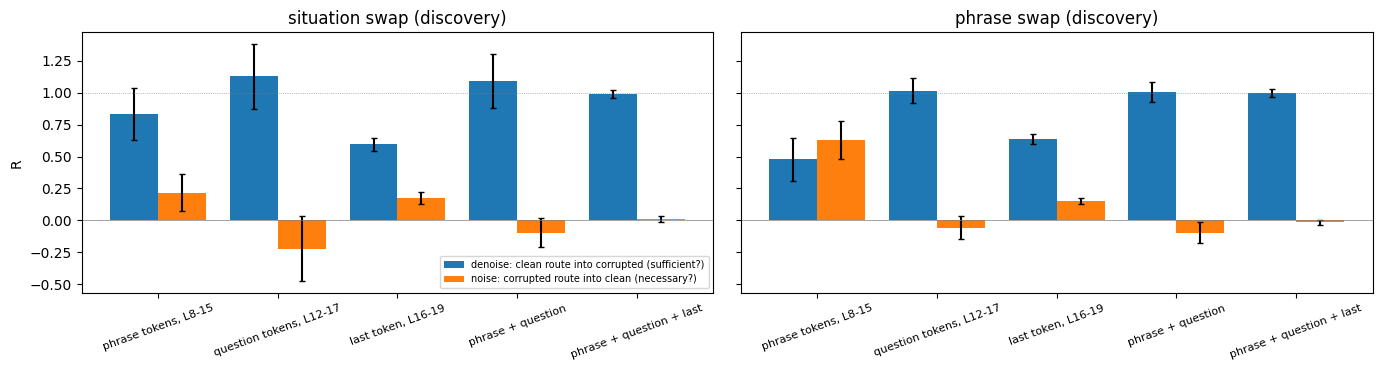

In [6]:
def routes(p):
    reg = p.clean.regions
    ph, qu, fi = reg["phrase"], reg["question"], reg["final"]
    return {
        "phrase tokens, L8-15": [(l, ph) for l in PHRASE_LAYERS],
        "question tokens, L12-17": [(l, qu) for l in QUESTION_LAYERS],
        "last token, L16-19": [(l, fi) for l in FINAL_LAYERS],
        "phrase + question": [(l, ph) for l in PHRASE_LAYERS] + [(l, qu) for l in QUESTION_LAYERS],
        "phrase + question + last": [(l, ph) for l in PHRASE_LAYERS] + [(l, qu) for l in QUESTION_LAYERS] + [(l, fi) for l in FINAL_LAYERS],
    }

def run_routes():
    out = {}
    for key, ps in PAIRS.items():
        out[key] = {mode: [route_patching(model, tok, p, routes(p), mode) for p in ps] for mode in ["denoise", "noise"]}
    return out

t0 = time.time()
RT = cached("routes", run_routes, sub=SUB)
print(f"{(time.time() - t0) / 60:.1f} min")
rows = []
for (e, split), res in RT.items():
    ps = PAIRS[(e, split)]
    for mode, lst in res.items():
        for name in lst[0]:
            r = np.array([R_(x[name], p) for x, p in zip(lst, ps)])
            rows.append(dict(experiment=e, split=split, mode=mode, route=name, R=r.mean(), se=r.std(ddof=1) / np.sqrt(len(r))))
RTT = pd.DataFrame(rows)
display(RTT.pivot_table(index=["experiment", "route"], columns=["mode", "split"], values="R", sort=False).round(3))

names = list(routes(PAIRS[("situation", "discovery")][0]))
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, e in zip(axes, ["situation", "phrase"]):
    x = np.arange(len(names))
    for j, mode in enumerate(["denoise", "noise"]):
        s = RTT[(RTT.experiment == e) & (RTT.split == "discovery") & (RTT["mode"] == mode)].set_index("route").loc[names]
        ax.bar(x + (j - 0.5) * 0.4, s.R, 0.4, yerr=1.96 * s.se, capsize=2,
               label="denoise: clean route into corrupted (sufficient?)" if mode == "denoise" else "noise: corrupted route into clean (necessary?)")
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, fontsize=8); ax.axhline(0, c="gray", lw=0.5); ax.axhline(1, c="gray", lw=0.5, ls=":")
    ax.set_title(f"{e} swap (discovery)")
axes[0].set_ylabel("R"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "routes.png"), dpi=150); plt.show()

## 4 · Movers: which heads bring the information into the phrase and the question tokens

Denoising, one head at a time, at the given positions (its output z at those positions from the clean run).

[saved]  /content/drive/MyDrive/sarcasm/03c_path_patching/Qwen2.5-7B-Instruct_data-v2/movers.pt
4.2 min


/tmp/ipykernel_2435/246313797.py:16: RuntimeWarning: Mean of empty slice
  m = np.nanmean(A, 0)                      # [L, H] (NaN outside the layers)


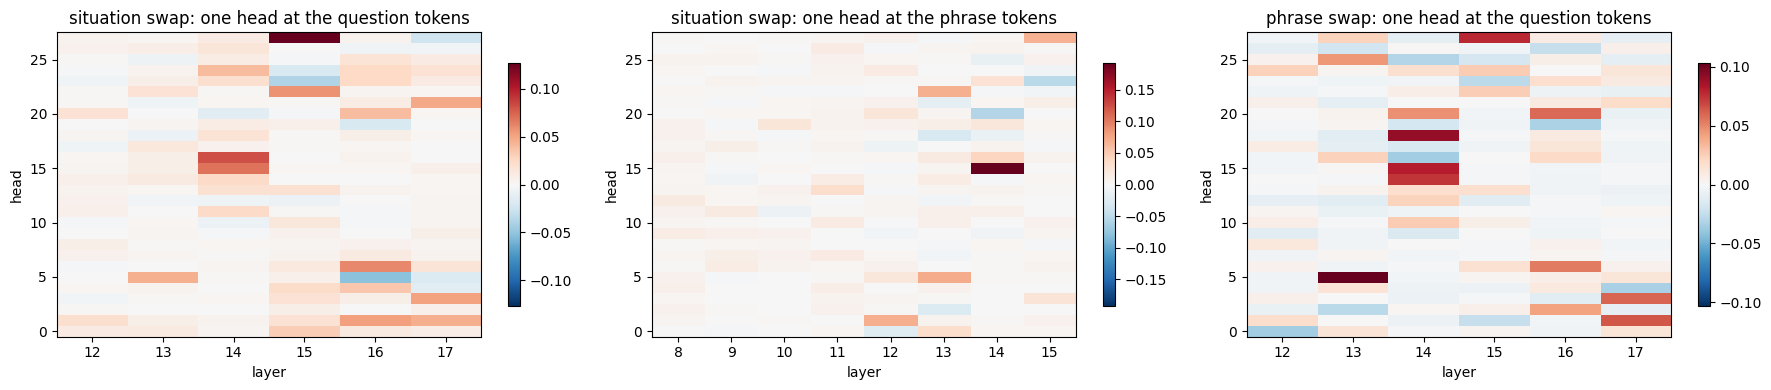

,experiment,positions,head,R
0,situation,question,a15.h27,0.127
1,situation,question,a14.h16,0.082
2,situation,question,a14.h15,0.070
3,situation,question,a16.h6,0.061
4,situation,question,a15.h22,0.058
5,situation,question,a16.h1,0.052
6,situation,question,a17.h3,0.051
7,situation,question,a17.h21,0.048
8,situation,phrase,a14.h15,0.193
9,situation,phrase,a13.h5,0.072


In [7]:
def run_movers():
    out = {}
    for e in ["situation", "phrase"]:
        ps = PAIRS[(e, "discovery")]
        out[(e, "question")] = np.stack([head_patching(model, tok, p, p.clean.regions["question"], layers=QUESTION_LAYERS) for p in ps])
        if e == "situation":
            out[(e, "phrase")] = np.stack([head_patching(model, tok, p, p.clean.regions["phrase"], layers=PHRASE_LAYERS) for p in ps])
    return out

t0 = time.time()
MV = cached("movers", run_movers, sub=SUB)
print(f"{(time.time() - t0) / 60:.1f} min")
fig, axes = plt.subplots(1, len(MV), figsize=(6 * len(MV), 4))
mrows = []
for ax, ((e, where), A) in zip(np.atleast_1d(axes), MV.items()):
    m = np.nanmean(A, 0)                      # [L, H] (NaN outside the layers)
    lays = QUESTION_LAYERS if where == "question" else PHRASE_LAYERS
    sub = m[lays]
    lim = np.nanmax(np.abs(sub))
    im = ax.imshow(sub.T, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim,
                   extent=[lays[0] - 0.5, lays[-1] + 0.5, -0.5, H - 0.5])
    ax.set_title(f"{e} swap: one head at the {where} tokens"); ax.set_xlabel("layer"); ax.set_ylabel("head")
    plt.colorbar(im, ax=ax, shrink=0.8)
    for f in np.argsort(-np.nan_to_num(sub).ravel())[:8]:
        l, h = np.unravel_index(f, sub.shape)
        mrows.append(dict(experiment=e, positions=where, head=f"a{lays[l]}.h{h}", R=float(sub[l, h])))
plt.tight_layout(); plt.savefig(os.path.join(results_dir(SUB), "movers.png"), dpi=150); plt.show()
MVT = pd.DataFrame(mrows)
display(MVT.round(3))

## Save

In [8]:
d = results_dir(SUB)
SWT.to_csv(os.path.join(d, "switch.csv"), index=False)
KOT.to_csv(os.path.join(d, "knockout.csv"), index=False)
RTT.to_csv(os.path.join(d, "routes.csv"), index=False)
MVT.to_csv(os.path.join(d, "movers_top.csv"), index=False)
json.dump(dict(model=MODEL, data=DATA, layer=LAYER, key_heads=KEY, pairs={f"{k[0]}/{k[1]}": len(v) for k, v in PAIRS.items()}),
          open(os.path.join(d, "summary.json"), "w"), indent=1)
print("saved to", d)

saved to /content/drive/MyDrive/sarcasm/03c_path_patching/Qwen2.5-7B-Instruct_data-v2
